# Capsule endoscopy lesion detector (YOLO11s, kyucapsule)
Run cells top to bottom. **Before cell 1:** right sidebar → Session options → set **Accelerator = GPU** (T4 x2 or P100) and **Internet = On**.
Cell 0 stops with a clear message if either is missing.

**Important:** training takes hours. Use **Save Version -> Save & Run All (Commit)** instead of running interactively, so it keeps going with the tab closed and `/kaggle/working` is kept in the version's Output tab. An interactive session that closes deletes everything in `/kaggle/working`.

In [1]:
# CELL 0 - check GPU + internet (stops early with a clear message)
import torch, urllib.request
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")
assert torch.cuda.is_available(), "No GPU. Session options -> Accelerator -> GPU T4 x2 (or P100), then re-run."
try:
    urllib.request.urlopen("https://pypi.org", timeout=10)
    print("Internet: ON")
except Exception as e:
    raise RuntimeError("Internet is OFF. Session options -> Internet -> On (Kaggle may ask for phone verification), then re-run. "
                       "pip, kagglehub and the pretrained YOLO weights all need it.") from e

GPU: Tesla T4
Internet: ON


In [2]:
# CELL 1 - install (output is shown so you can see any failure)
import subprocess, sys, importlib
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.3.223", "kagglehub"],
                   capture_output=True, text=True)
print("pip returncode:", r.returncode)
print(r.stdout[-1500:]); print(r.stderr[-1500:])
assert r.returncode == 0, "pip failed - read the message printed above"
importlib.invalidate_caches()
import ultralytics
print("ultralytics", ultralytics.__version__)

pip returncode: 0


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics 8.3.223


In [3]:
# CELL 2 - config
import os, re, json, time, random, shutil, hashlib
from pathlib import Path
import numpy as np, pandas as pd
os.environ["WANDB_DISABLED"] = "true"; os.environ["WANDB_MODE"] = "disabled"

CFG = dict(
    MODEL="yolo11s.pt",   # "yolo11m.pt" = a bit more accurate, ~2x slower
    IMGSZ=640, BATCH=16, EPOCHS=50, TRAIN_HOURS=None,   # set TRAIN_HOURS=8 to cap by time instead of epochs
    SEED=0, BLOCK=100, TRIALS=3000, RUN_NAME="cap_y11s",
)
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./work")
DATA, RUNS = WORK / "data", WORK / "runs"
WORK.mkdir(parents=True, exist_ok=True)
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"])
print("work dir:", WORK.resolve())

work dir: /kaggle/working


In [4]:
# CELL 3 - download dataset, pair images with label files, read class names
import kagglehub
root = Path(kagglehub.dataset_download("capsuleyolo/kyucapsule"))
print("dataset at:", root)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
AUX = {"classes.txt", "labels.txt", "obj.names", "readme.txt", "train.txt", "val.txt", "test.txt"}
files = [p for p in root.rglob("*") if p.is_file()]
images = sorted(p for p in files if p.suffix.lower() in IMG_EXT)
label_set = {str(p) for p in files if p.suffix.lower() == ".txt" and p.name.lower() not in AUX}
by_stem = {}
for s in label_set:
    by_stem.setdefault(Path(s).stem, []).append(s)

def find_label(img):
    parts = list(img.parts)
    for i in range(len(parts) - 1, -1, -1):
        if parts[i].lower() == "images":
            for repl in ("labels", "Labels", "LABELS"):
                alt = parts.copy(); alt[i] = repl
                q = str(Path(*alt).with_suffix(".txt"))
                if q in label_set: return q
            break
    q = str(img.with_suffix(".txt"))
    if q in label_set: return q
    c = by_stem.get(img.stem, [])
    return c[0] if len(c) == 1 else ""

rows = []
for im in images:
    nums = re.findall(r"\d+", im.stem)
    rows.append(dict(image=str(im), label=find_label(im), num=int(nums[-1]) if nums else -1))
man = pd.DataFrame(rows).sort_values(["num", "image"]).reset_index(drop=True)
assert len(man) > 0, "no images found - check the dataset path printed above"
print(f"{len(man)} images | {(man.label == '').sum()} without a label file (treated as background)")

csv = next(root.rglob("all_annotation.csv"), None)
if csv is not None:
    ann = pd.read_csv(csv)
    cols = list(ann.columns[2:14]); ids = [int(ann.iloc[0][c]) for c in cols]
    NAMES = [n for _, n in sorted(zip(ids, cols))]
else:
    NAMES = [f"class_{i}" for i in range(12)]
    print("WARNING: all_annotation.csv not found, using generic class names")
print("classes:", NAMES)

dataset at: /kaggle/input/datasets/capsuleyolo/kyucapsule
18481 images | 0 without a label file (treated as background)
classes: ['angiodysplasia', 'erosion', 'stenosis', 'lymphangiectasia', 'lymph follicle', 'SMT', 'polyp-like', 'bleeding', 'diverticulum', 'erythema', 'foreign body', 'vein']


In [5]:
# CELL 4 - leakage-safe split (blocks of consecutive frames) + build YOLO folders
# Capsule frames come in video order, so neighbouring frames look almost identical. A random split would put
# near-copies in train AND test and inflate accuracy. Here whole blocks of 100 consecutive frames stay together,
# and byte-identical images always follow their first copy.
from concurrent.futures import ThreadPoolExecutor
import yaml
nb = len(NAMES)
cnt = np.zeros((len(man), nb), dtype=np.int64)
for i, lb in enumerate(man.label):
    if lb:
        for ln in Path(lb).read_text().splitlines():
            p = ln.split()
            if len(p) == 5:
                try: c = int(float(p[0]))
                except ValueError: continue
                if 0 <= c < nb: cnt[i, c] += 1

def md5(p): return hashlib.md5(Path(p).read_bytes()).hexdigest()
with ThreadPoolExecutor(16) as ex:
    man["md5"] = list(ex.map(md5, man.image))

blk = np.arange(len(man)) // CFG["BLOCK"]; nB = int(blk.max()) + 1
F = np.zeros((nB, 1 + nb)); np.add.at(F, blk, np.column_stack([np.ones(len(man)), cnt]))
tot = F.sum(0); tgt = tot * 0.1
rng = np.random.default_rng(CFG["SEED"]); best = None
for _ in range(CFG["TRIALS"]):          # pick the block assignment whose val/test class mix is closest to 10 %
    perm = rng.permutation(nB); cs = np.cumsum(F[perm], axis=0)
    k1 = int(np.searchsorted(cs[:, 0], tgt[0])) + 1
    k2 = int(np.searchsorted(cs[:, 0], 2 * tgt[0])) + 1
    te, va = cs[k1 - 1], cs[k2 - 1] - cs[k1 - 1]
    den = np.maximum(tot, 1)
    cost = (np.abs(te - tgt) / den).sum() + (np.abs(va - tgt) / den).sum()
    if best is None or cost < best[0]: best = (cost, perm, k1, k2)
_, perm, k1, k2 = best
sp = np.empty(nB, dtype=object); sp[perm[:k1]] = "test"; sp[perm[k1:k2]] = "val"; sp[perm[k2:]] = "train"
man["split"] = sp[blk]
man["split"] = man.groupby("md5")["split"].transform("first")

summary = pd.DataFrame({s: [int((man.split == s).sum())] + cnt[(man.split == s).to_numpy()].sum(0).tolist()
                        for s in ("train", "val", "test")}, index=["images"] + NAMES)
print(summary.to_string())

shutil.rmtree(DATA, ignore_errors=True)
for s in ("train", "val", "test"):
    (DATA / s / "images").mkdir(parents=True); (DATA / s / "labels").mkdir(parents=True)
def put(r):
    d = DATA / r.split
    shutil.copy2(r.image, d / "images" / Path(r.image).name)
    dst = d / "labels" / (Path(r.image).stem + ".txt")
    if r.label: shutil.copy2(r.label, dst)
    else: dst.write_text("")
with ThreadPoolExecutor(16) as ex:
    list(ex.map(put, man.itertuples()))
(DATA / "data.yaml").write_text(yaml.safe_dump(
    dict(path=str(DATA), train="train/images", val="val/images", test="test/images", names=dict(enumerate(NAMES))),
    sort_keys=False))
man.drop(columns=["image", "label"]).to_csv(WORK / "split.csv", index=False)
print("ready:", DATA / "data.yaml")

                  train   val  test
images            14781  1800  1900
angiodysplasia      783    85    63
erosion            4919   610   458
stenosis            359    46    40
lymphangiectasia    493    61    55
lymph follicle     5515   537   736
SMT                 475    54    13
polyp-like         2448   280   502
bleeding            751    63    54
diverticulum         40     9     5
erythema            761    86   172
foreign body       1369   123   154
vein                670   112   132
ready: /kaggle/working/data/data.yaml


In [6]:
# CELL 5 - train (COCO-pretrained YOLO11s, fine-tuned). Watch mAP50 on the val split each epoch.
from ultralytics import YOLO, settings
try: settings.update({"wandb": False})
except Exception: pass

model = YOLO(CFG["MODEL"])
kw = dict(
    data=str(DATA / "data.yaml"), imgsz=CFG["IMGSZ"], batch=CFG["BATCH"], epochs=CFG["EPOCHS"],
    device=0, workers=4, optimizer="SGD", lr0=0.01, cos_lr=True, patience=30, close_mosaic=10,
    flipud=0.5, fliplr=0.5, degrees=10, mosaic=1.0, mixup=0.0,   # capsule frames have no fixed "up"
    seed=CFG["SEED"], amp=True, plots=True,
    project=str(RUNS), name=CFG["RUN_NAME"], exist_ok=True,
)
if CFG["TRAIN_HOURS"]: kw["time"] = CFG["TRAIN_HOURS"]   # overrides epochs
model.train(**kw)
print("best weights:", RUNS / CFG["RUN_NAME"] / "weights" / "best.pt")

# make a download-ready zip IMMEDIATELY, so nothing depends on later cells or on variables surviving a restart
import zipfile
_w, _run = Path(WORK), RUNS / CFG["RUN_NAME"]
shutil.copy2(_run / "weights" / "best.pt", _w / "capsule_best.pt")
with zipfile.ZipFile(_w / "capsule_model.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in (_w / "capsule_best.pt", _run / "results.csv", _run / "results.png"):
        if f.exists(): z.write(f, f.name)
print("saved:", _w / "capsule_model.zip")

New https://pypi.org/project/ultralytics/8.4.212 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.223 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=cap_y11s, nbs=64, nms=False, opset=None

In [7]:
# CELL 6 - honest evaluation on the held-out TEST split (best.pt was picked using val, so test is the number to report)
from ultralytics import YOLO
best_pt = RUNS / CFG["RUN_NAME"] / "weights" / "best.pt"
m = YOLO(str(best_pt))
res = {}
for split in ("val", "test"):
    r = m.val(data=str(DATA / "data.yaml"), split=split, imgsz=CFG["IMGSZ"], batch=CFG["BATCH"],
              conf=0.001, iou=0.6, plots=False, verbose=False)
    res[split] = r
    print(f"{split:5s} mAP50={r.box.map50:.3f}  mAP50-95={r.box.map:.3f}  P={r.box.mp:.3f}  R={r.box.mr:.3f}")
r = res["test"]
print("\nper-class AP50 on test:")
for i, c in enumerate(r.box.ap_class_index):
    print(f"  {r.names[int(c)]:18s} {r.box.ap50[i]:.3f}")
try:
    f1 = r.box.f1_curve.mean(0); BEST_CONF = float(r.box.px[f1.argmax()])
    print(f"\nconfidence with best mean F1: {BEST_CONF:.2f}  <- use this as the website's default threshold")
except Exception:
    BEST_CONF = 0.25

Ultralytics 8.3.223 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,417,444 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1368.7±499.5 MB/s, size: 62.8 KB)
val: Scanning /kaggle/working/data/val/labels.cache... 1800 images, 488 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1800/1800 3.4Mit/s 0.0s0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 113/113 4.3it/s 26.3s0.2s
                   all       1800       2066       0.58      0.569      0.524      0.294
Speed: 0.8ms preprocess, 11.7ms inference, 0.0ms loss, 0.7ms postprocess per image
val   mAP50=0.524  mAP50-95=0.294  P=0.580  R=0.569
Ultralytics 8.3.223 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1256.7±357.8 MB/s, size: 85.4 KB)
val: Scanning /kaggle/working/data/test/labels... 1900 images, 682 backgrounds, 0 

{'model': 'yolo11s.pt', 'imgsz': 640, 'default_conf': 0.19, 'test_map50': 0.4494, 'test_map50_95': 0.2461}
size (MB): 18.2


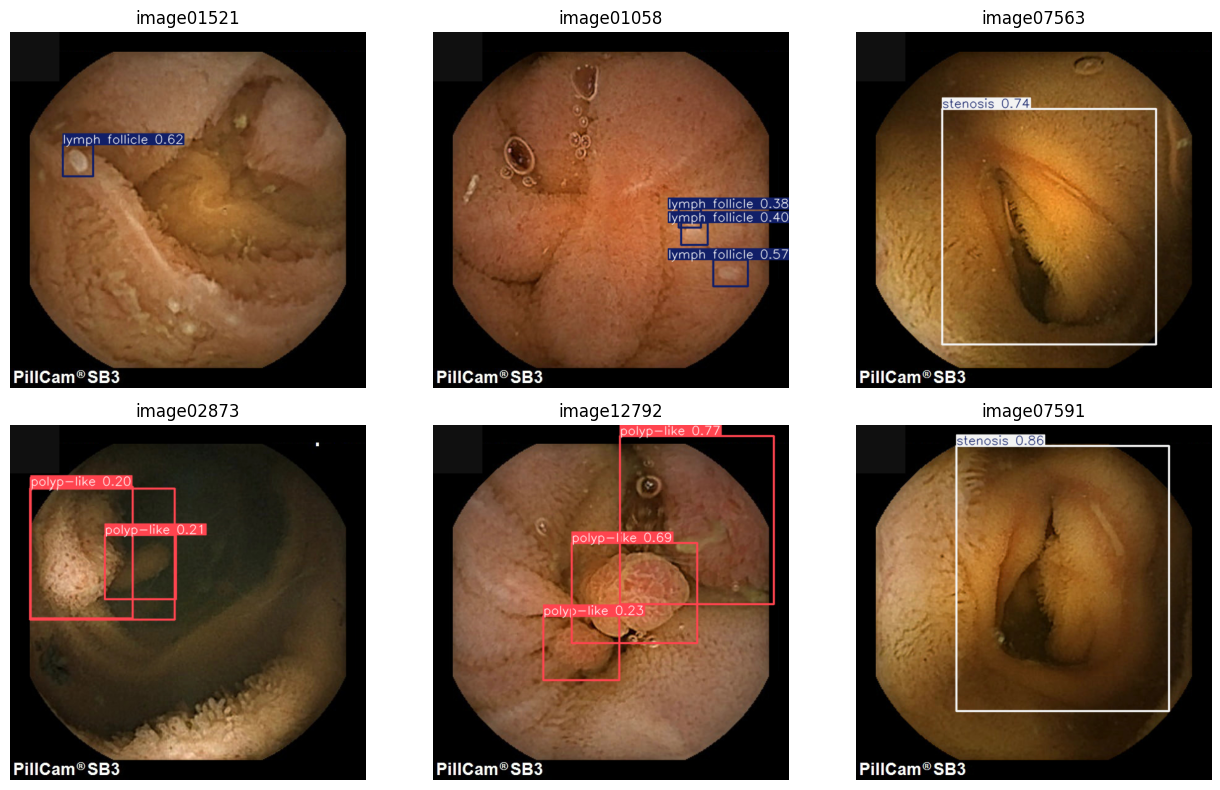

In [8]:
# CELL 7 - package the model for download (Output tab -> capsule_model.zip)
import zipfile
final = WORK / "capsule_best.pt"
shutil.copy2(best_pt, final)
(WORK / "classes.json").write_text(json.dumps(NAMES, indent=1))
meta = dict(model=CFG["MODEL"], imgsz=CFG["IMGSZ"], default_conf=round(BEST_CONF, 2),
            test_map50=round(float(res["test"].box.map50), 4), test_map50_95=round(float(res["test"].box.map), 4))
(WORK / "model_info.json").write_text(json.dumps(meta, indent=1))
with zipfile.ZipFile(WORK / "capsule_model.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in (final, WORK / "classes.json", WORK / "model_info.json",
              RUNS / CFG["RUN_NAME"] / "results.csv", RUNS / CFG["RUN_NAME"] / "results.png",
              RUNS / CFG["RUN_NAME"] / "confusion_matrix_normalized.png"):
        if Path(f).exists(): z.write(f, Path(f).name)
print(meta); print("size (MB):", round((WORK / "capsule_model.zip").stat().st_size / 1e6, 1))

# quick look at a few test predictions
import matplotlib.pyplot as plt, cv2
lab = [p for p in (DATA / "test" / "labels").glob("*.txt") if p.stat().st_size > 0][:6]
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for a, l in zip(ax.ravel(), lab):
    img = next((DATA / "test" / "images").glob(l.stem + ".*"))
    out = m.predict(str(img), imgsz=CFG["IMGSZ"], conf=BEST_CONF, verbose=False)[0].plot()
    a.imshow(out[..., ::-1]); a.set_title(l.stem); a.axis("off")
plt.tight_layout(); plt.show()